First 5 rows:
    mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter 

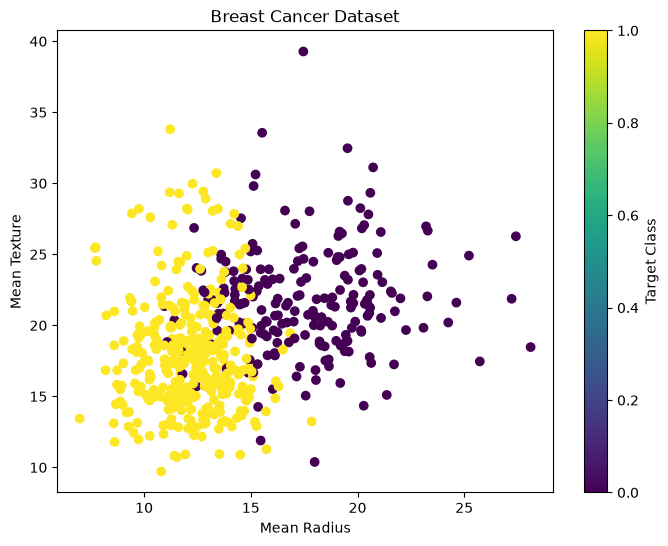


Training Shape: (455, 30)
Testing Shape: (114, 30)

DECISION TREE
Accuracy: 0.9385964912280702
              precision    recall  f1-score   support

   malignant       0.93      0.90      0.92        42
      benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114


BAGGING
Accuracy: 0.9385964912280702
              precision    recall  f1-score   support

   malignant       0.93      0.90      0.92        42
      benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114


BOOSTING
Accuracy: 0.956140350877193
              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accura

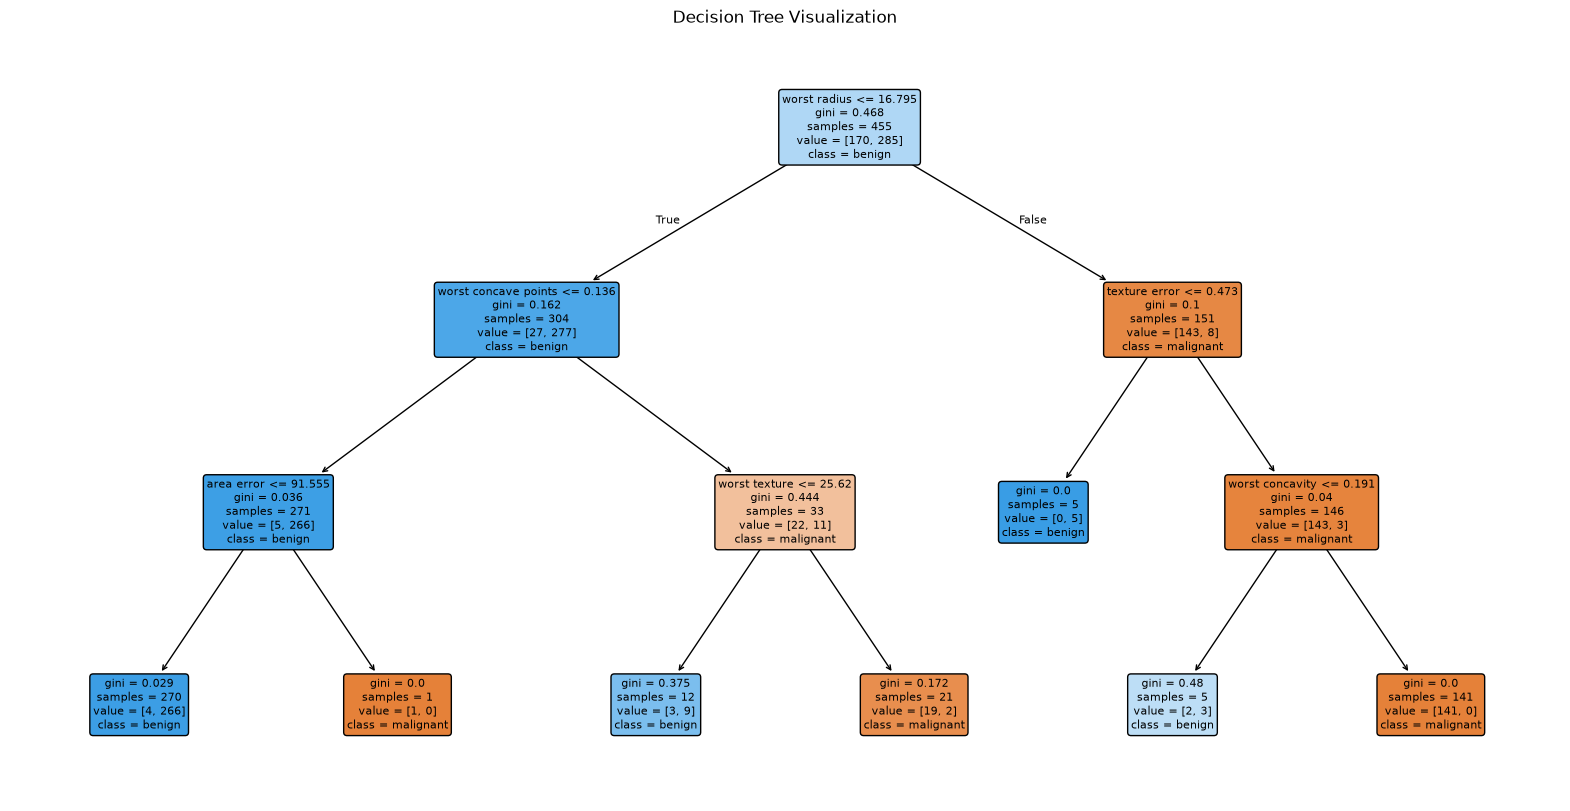


ACCURACY COMPARISON
           Model  Accuracy
0  Decision Tree  0.938596
1        Bagging  0.938596
2       Boosting  0.956140
3  Random Forest  0.956140


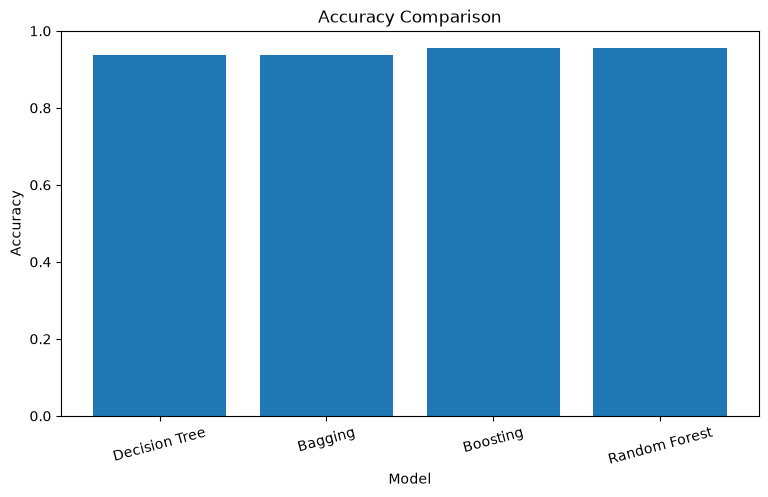

In [3]:
#Experiment 6 – Breast Cancer Classification using Decision Tree, Bagging, Boosting and Random Forest
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="Target")

print("First 5 rows:\n", X.head())
print("\nShape:", X.shape)
print("\nClass Distribution:\n", y.value_counts())
print("\nTarget Classes:", data.target_names)

plt.figure(figsize=(8, 6))
plt.scatter(X["mean radius"], X["mean texture"], c=y, cmap="viridis")
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Breast Cancer Dataset")
plt.colorbar(label="Target Class")
plt.show()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("\nTraining Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

models = {
    "Decision Tree": DecisionTreeClassifier(
        criterion="gini", max_depth=3, random_state=42
    ),

    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=50, random_state=42
    ),

    "Boosting": AdaBoostClassifier(
        n_estimators=50, random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    )
}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    acc = accuracy_score(y_test, pred)

    results.append((name, acc))

    print("\n" + "=" * 50)
    print(name.upper())
    print("=" * 50)

    print("Accuracy:", acc)

    print(classification_report(
        y_test, pred, target_names=data.target_names
    ))

plt.figure(figsize=(20, 10))

plot_tree(
    models["Decision Tree"],
    feature_names=data.feature_names,
    class_names=data.target_names,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Visualization")
plt.show()

results = pd.DataFrame(results, columns=["Model", "Accuracy"])

print("\n" + "=" * 50)
print("ACCURACY COMPARISON")
print("=" * 50)

print(results)

plt.figure(figsize=(9, 5))

plt.bar(results["Model"], results["Accuracy"])

plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison")

plt.ylim(0, 1)
plt.xticks(rotation=15)

plt.show()


Regression Model Comparison
           Model           MSE          RMSE  R² Score
0  Decision Tree  4.126306e+09  64236.327078  0.485341
1        Bagging  3.876781e+09  62263.801160  0.516463
2       Boosting  4.093057e+09  63977.003893  0.489488
3  Random Forest  3.857947e+09  62112.370685  0.518812


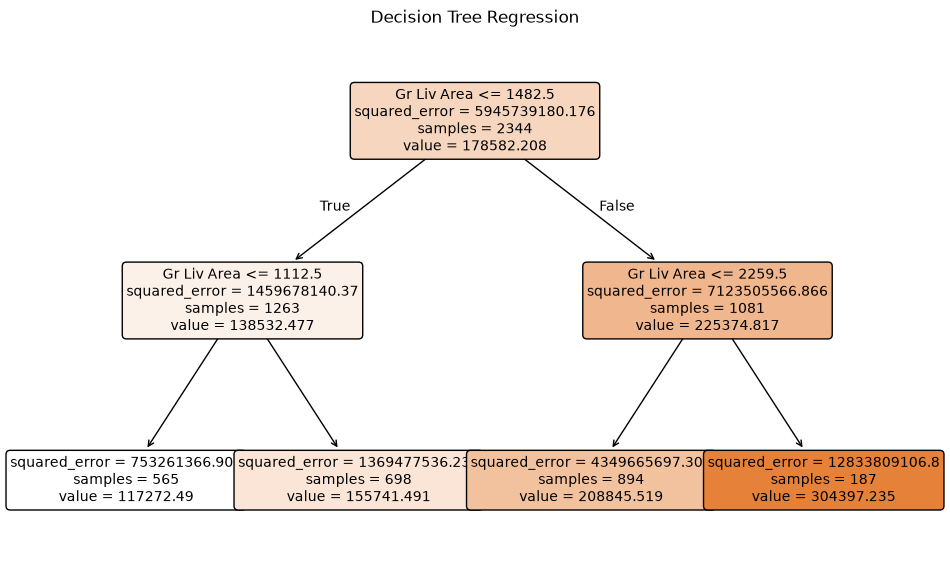

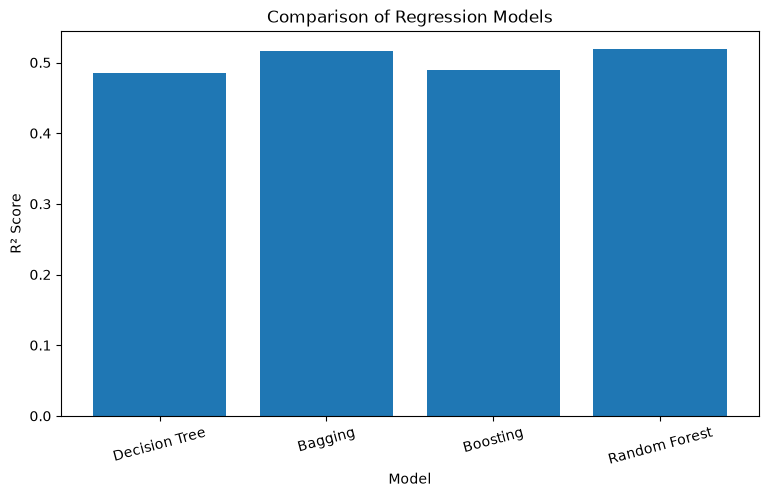

In [5]:
#Experiment 6 – Problem 2: Ames Housing Dataset – Regression Model Comparison
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import BaggingRegressor, GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

data = pd.read_csv(r"C:\Users\ASUS\Downloads\AmesHousing.csv")

X = data[["Gr Liv Area"]]
y = data["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "Decision Tree": DecisionTreeRegressor(max_depth=2, random_state=42),

    "Bagging": BaggingRegressor(
        estimator=DecisionTreeRegressor(max_depth=2),
        n_estimators=50, random_state=42
    ),

    "Boosting": GradientBoostingRegressor(
        n_estimators=50, max_depth=2, random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100, max_depth=2, random_state=42
    )
}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    mse = mean_squared_error(y_test, pred)
    rmse = mse ** 0.5
    r2 = r2_score(y_test, pred)

    results.append((name, mse, rmse, r2))


results = pd.DataFrame(
    results,
    columns=["Model", "MSE", "RMSE", "R² Score"]
)

print("\nRegression Model Comparison")
print("=" * 60)
print(results)

plt.figure(figsize=(12, 7))

plot_tree(
    models["Decision Tree"],
    feature_names=["Gr Liv Area"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree Regression")
plt.show()

plt.figure(figsize=(9, 5))

plt.bar(results["Model"], results["R² Score"])

plt.xlabel("Model")
plt.ylabel("R² Score")
plt.title("Comparison of Regression Models")
plt.xticks(rotation=15)

plt.show()

In [ ]:

import pandas as pd
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

data = {
    'Weather': ['Sunny','Sunny','Overcast','Rainy','Rainy','Rainy','Overcast','Sunny','Sunny','Rainy','Sunny','Overcast','Overcast','Rainy'],
    'Temperature': ['Hot','Hot','Hot','Mild','Cool','Cool','Cool','Mild','Cool','Mild','Mild','Mild','Hot','Mild'],
    'Wind': ['Weak','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Strong'],
    'Play': ['No','No','Yes','Yes','Yes','No','Yes','No','Yes','Yes','Yes','Yes','Yes','No']
}

df = pd.DataFrame(data)
print(df)

X = df[['Weather', 'Temperature', 'Wind']]
y = df['Play']

pre = ColumnTransformer([
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), X.columns)
])

X = pre.fit_transform(X)
features = pre.get_feature_names_out()

print("Encoded Feature:",X)
print("Feature names:",features)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
print("Accuracy on the test set:", accuracy_score(y_test, y_pred))

plot_tree(clf, filled=True, feature_names=features,
          class_names=['No Play', 'Play'])
plt.title("Decision Tree for Playing Game")
plt.show()

Iris Dataset Features (first 5 rows):
    sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Iris Dataset Target (first 5 rows):
 0    0
1    0
2    0
3    0
4    0
dtype: int64

Target Names (species): ['setosa' 'versicolor' 'virginica']

Iris Training set size: 105
Iris Test set size: 45

Decision Tree Classifier for Iris dataset trained successfully with max_depth=3.

Accuracy on the Iris test set with max_depth=3: 1.00


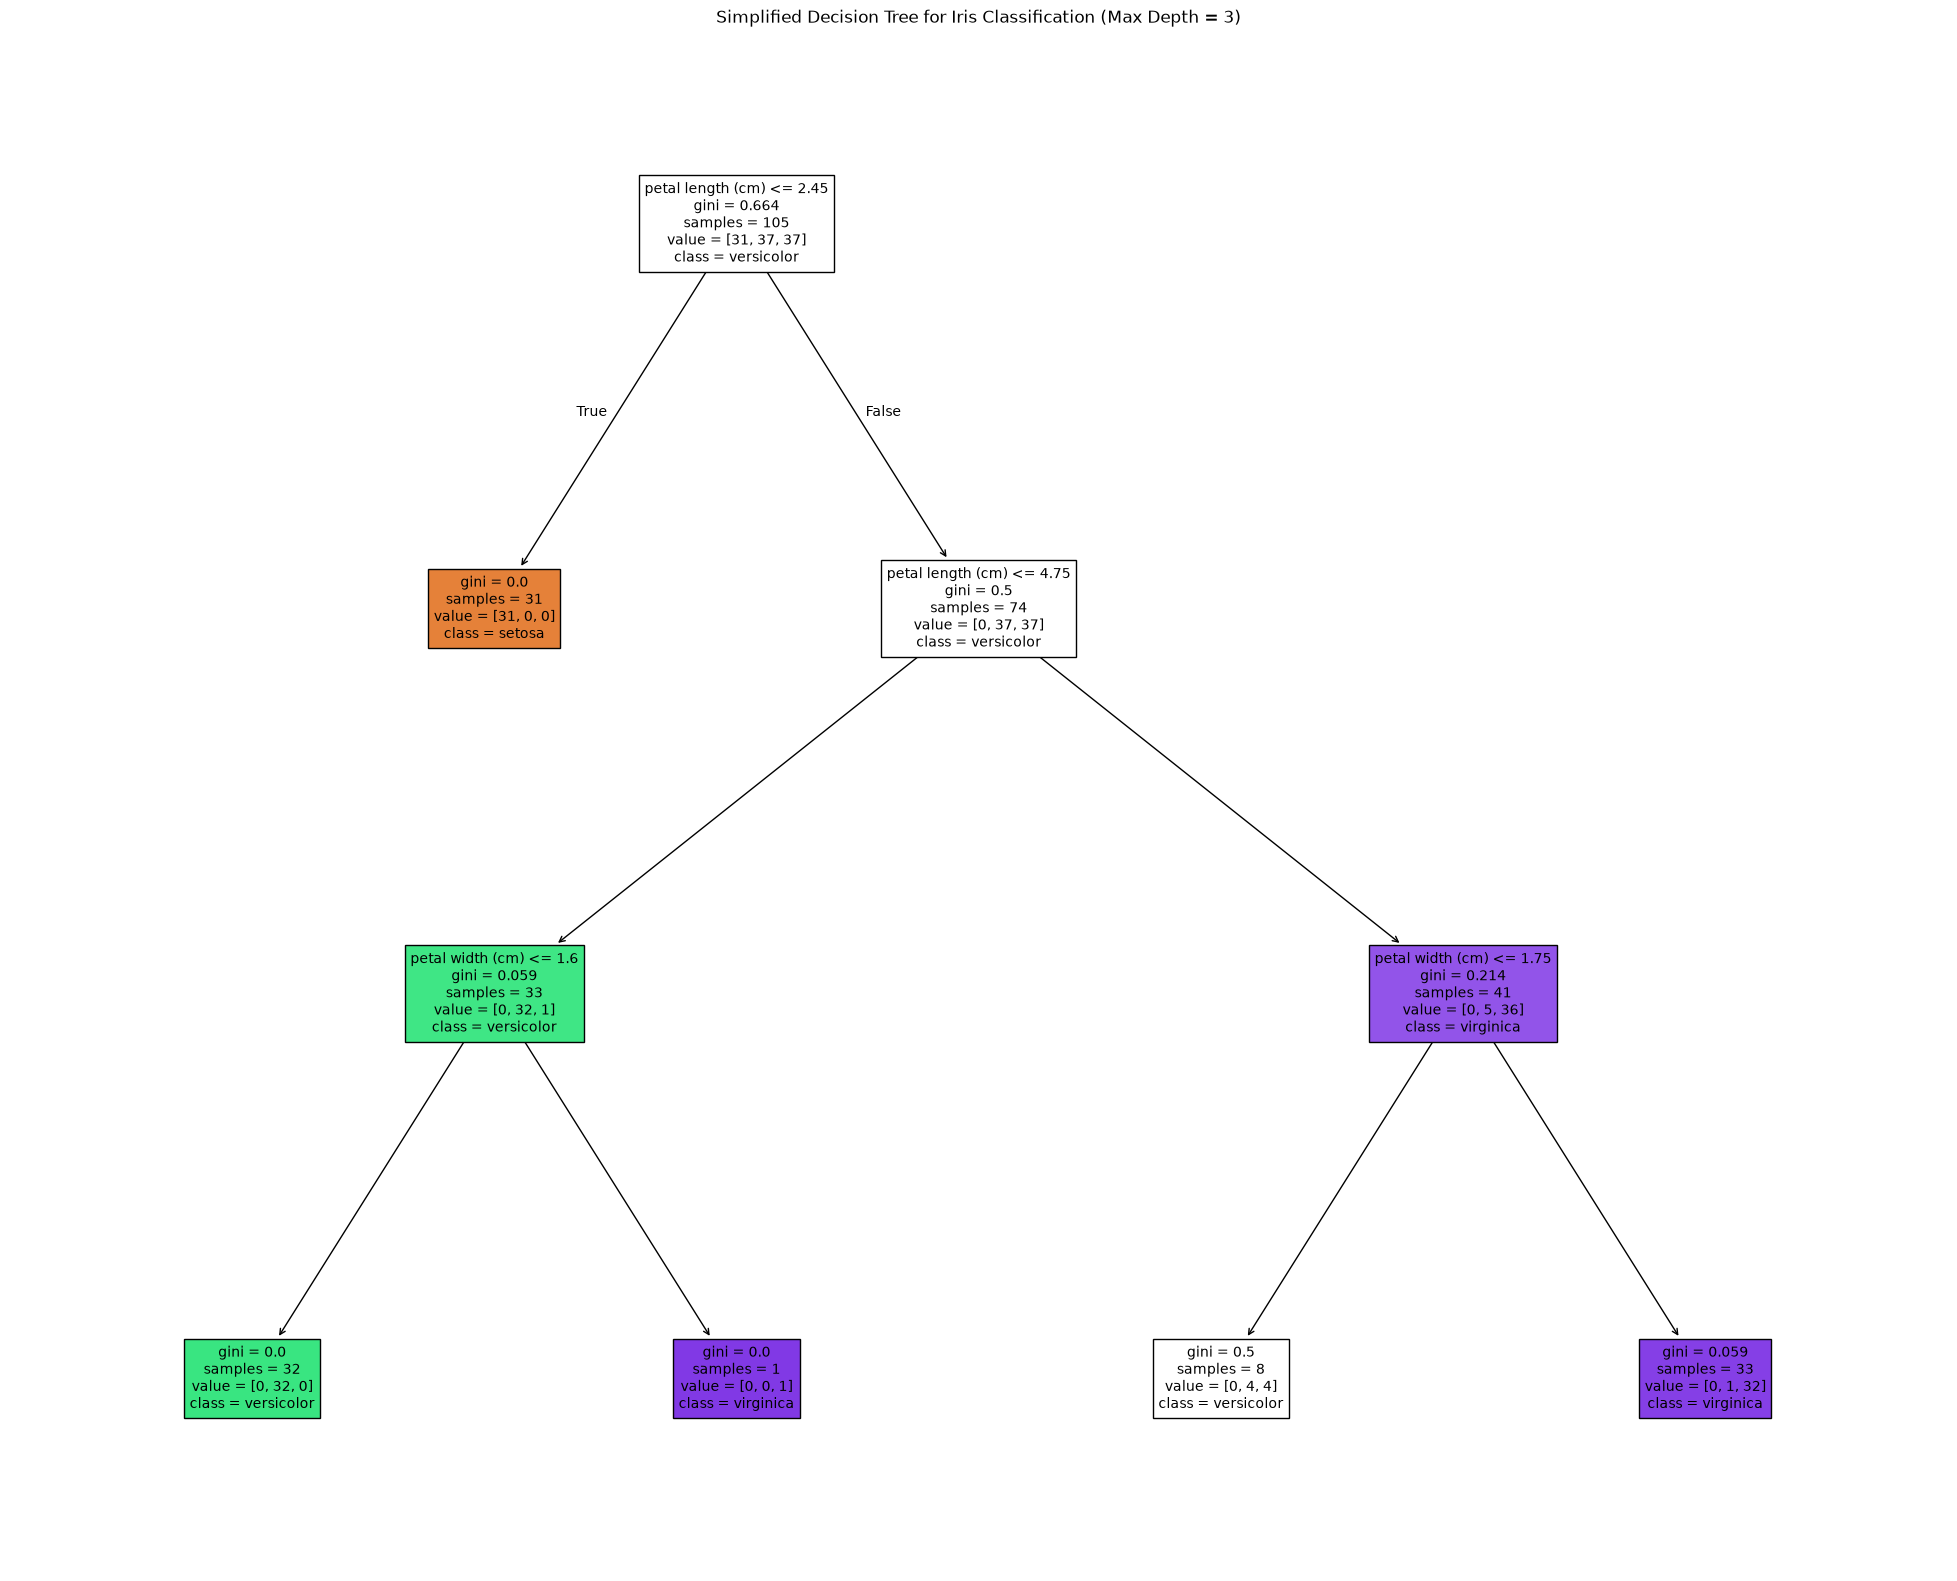

In [ ]:
#Experiment 2: Decision Tree Classifier using Iris Dataset

from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import pandas as pd

iris = load_iris()
X_iris = pd.DataFrame(
    iris.data, columns=iris.feature_names
)
y_iris = pd.Series(iris.target)
print("Iris Dataset Features (first 5 rows):\n",
      X_iris.head())

print("\nIris Dataset Target (first 5 rows):\n",
      y_iris.head())

print("\nTarget Names (species):", iris.target_names)

X_train_iris, X_test_iris, y_train_iris, y_test_iris = (
    train_test_split(
        X_iris, y_iris, test_size=0.3, random_state=42
    )
)
print(f"\nIris Training set size: {len(X_train_iris)}")
print(f"Iris Test set size: {len(X_test_iris)}")
clf_iris = DecisionTreeClassifier(
    max_depth=3, random_state=42
)
clf_iris.fit(X_train_iris, y_train_iris)
print("\nDecision Tree Classifier for Iris dataset "
      "trained successfully with max_depth=3.")
y_pred_iris = clf_iris.predict(X_test_iris)

accuracy_iris = accuracy_score(
    y_test_iris, y_pred_iris
)
print(f"\nAccuracy on the Iris test set with "
      f"max_depth=3: {accuracy_iris:.2f}")
plt.figure(figsize=(25, 20))
plot_tree(
    clf_iris,
    filled=True,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    fontsize=10
)

plt.title(
    "Simplified Decision Tree for Iris Classification "
    "(Max Depth = 3)"
)
plt.show()
